# **OOD Detection with K-NN**

## **1. Preperation and Imports**

In [36]:
import torch
import numpy as np
import torchvision
import matplotlib.pyplot as plt
import kagglehub
from transformers import AutoImageProcessor, AutoModel
import os

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [84]:
from huggingface_hub import login
login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [85]:
model_name = "facebook/dinov3-vitl16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    #Load Model with Memory Optimization and Eager Attention
    # We strictly need eager attention to capture the attention weights
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=torch.float32,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    #Load Processor
    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    #Verify Layer Count
    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        #Fallback for flat architectures
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

Loading flagship model: facebook/dinov3-vitl16-pretrain-lvd1689m
Targeting Architecture: 40 Layers, 4096 Embedding Dim


config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/1.21G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Model loaded. Number of register tokens identified: 4
Success! Model loaded with 24 layers.


## **2. Dataset load**
Because we have all the features saved we just need to load them.

### **2.1 Raw from computed features**

In [3]:
from google.colab import drive
import gc

In [5]:
print("🔌 Connecting to Google Drive...")
drive.mount('/content/drive')

🔌 Connecting to Google Drive...
Mounted at /content/drive


In [6]:
BASE_PATH = '/content/drive/MyDrive/BC/features/'
TRAIN_FEATURES_FILE = BASE_PATH + 'caltech101_train_flagship_features.pt'
TEST_FEATURES_FILE = BASE_PATH + 'caltech101_test_flagship_features.pt'

In [7]:
try:
    # ==========================================
    # 1. LOAD TRAIN FLAGSHIP DATA
    # ==========================================
    print(f"\n⏳ Loading Train Data from {TRAIN_FEATURES_FILE}...")
    raw_train_data = torch.load(TRAIN_FEATURES_FILE, map_location="cpu")

    # Check if it's a dictionary (containing both features and labels)
    if isinstance(raw_train_data, dict):
        caltech_train_features = raw_train_data.get('features', raw_train_data)
        caltech_train_labels = raw_train_data.get('labels', None)
    else:
        caltech_train_features = raw_train_data
        caltech_train_labels = None

    print(f"✅ Train Features loaded! (Type: {type(caltech_train_features)})")
    if caltech_train_labels is not None:
         print(f"✅ Train Labels also found inside the file!")

    del raw_train_data
    gc.collect() # Empty the RAM trash

    # ==========================================
    # 2. LOAD TEST FLAGSHIP DATA
    # ==========================================
    print(f"\n⏳ Loading Test Data from {TEST_FEATURES_FILE}...")
    raw_test_data = torch.load(TEST_FEATURES_FILE, map_location="cpu")

    if isinstance(raw_test_data, dict):
        caltech_test_features = raw_test_data.get('features', raw_test_data)
        caltech_test_labels = raw_test_data.get('labels', None)
    else:
        caltech_test_features = raw_test_data
        caltech_test_labels = None

    print(f"✅ Test Features loaded! (Type: {type(caltech_test_features)})")
    if caltech_test_labels is not None:
         print(f"✅ Test Labels also found inside the file!")

    del raw_test_data
    gc.collect()

    print("\n🎉 SUCCESS! Both Flagship files are fully loaded into memory.")

except RuntimeError as e:
    print(f"\n❌ CRASH: PyTorch ran out of RAM! Error: {e}")
    print("The Flagship file is too big for this Colab instance. Time to use the local slicer script!")
except FileNotFoundError as e:
    print(f"\n❌ ERROR: Colab couldn't find the file! Double check the name in Google Drive. Error: {e}")


⏳ Loading Train Data from /content/drive/MyDrive/BC/features/caltech101_train_flagship_features.pt...
✅ Train Features loaded! (Type: <class 'list'>)
✅ Train Labels also found inside the file!

⏳ Loading Test Data from /content/drive/MyDrive/BC/features/caltech101_test_flagship_features.pt...
✅ Test Features loaded! (Type: <class 'list'>)
✅ Test Labels also found inside the file!

🎉 SUCCESS! Both Flagship files are fully loaded into memory.


### **2.2 Download**

In [37]:
print("📥 Downloading and initializing the Caltech-101 Dataset...")

# Create a data directory if it doesn't exist
os.makedirs('./data', exist_ok=True)

# Download the dataset (if it's already downloaded, this just loads it instantly)
caltech_full = torchvision.datasets.Caltech101(root='./data', download=True)

# Extract the official string names for all 101 categories
class_names = caltech_full.categories

print("✅ Initialization Complete!")
print("========================================================")
print(f"🖼️ Total Images Available: {len(caltech_full)}")
print(f"🏷️ Total Classes Found:    {len(class_names)}")
print(f"🔍 First 5 Classes:        {class_names[:5]}")
print("========================================================")

📥 Downloading and initializing the Caltech-101 Dataset...
✅ Initialization Complete!
🖼️ Total Images Available: 8367
🏷️ Total Classes Found:    95
🔍 First 5 Classes:        ['Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion']


## **3. K-NN**

### **3.1 Imports**

In [10]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 92.0 MB/s eta 0:00:00


In [11]:
import faiss
import numpy as np
import time
import torch

### **3.2 Helping functions**

In [12]:
def to_numpy_array(data):
    if torch.is_tensor(data):
        return data.cpu().numpy()
    elif isinstance(data, list):
        if torch.is_tensor(data[0]):
            # If it's a list of tensors, stack them
            return torch.stack(data).cpu().numpy()
        # If it's already a list of numpy arrays
        return np.array(data)
    return data

In [24]:
def flatten_labels(labels):
    if torch.is_tensor(labels):
        return labels.cpu().numpy().flatten()
    elif isinstance(labels, list):
        if torch.is_tensor(labels[0]):
            return torch.tensor(labels).cpu().numpy().flatten()
        return np.array(labels).flatten()
    return labels

In [110]:
def get_class_name(idx):
    if idx < len(class_names):
        return class_names[idx]
    return f"Class {idx}"

### **3.3 Clustering**

In [13]:
train_feats_np = to_numpy_array(caltech_train_features)
test_feats_np = to_numpy_array(caltech_test_features)

In [15]:
flat_train = train_feats_np.reshape(-1, train_feats_np.shape[-1]).astype(np.float32)

In [16]:
print(f"\n🧠 Phase 2: Training FAISS K-Means (K=1024) on {len(flat_train)} patches...")
k = 1024
d = flat_train.shape[1] # Dimension (4096)

start_time = time.time()
use_gpu = faiss.get_num_gpus() > 0
kmeans = faiss.Kmeans(d, k, niter=20, verbose=False, gpu=use_gpu)
kmeans.train(flat_train)


🧠 Phase 2: Training FAISS K-Means (K=1024) on 1360436 patches...


np.float64(12951997.0)

### **3.4 Histograms**

In [17]:
index = faiss.IndexFlatL2(d)
index.add(kmeans.centroids)
print(f"✅ Dictionary built in {time.time() - start_time:.1f} seconds!")

✅ Dictionary built in 387.5 seconds!


In [18]:
def build_histograms(features_array):
    hists = []
    for feats in features_array:
        feats_f32 = feats.reshape(-1, d).astype(np.float32)
        _, I = index.search(feats_f32, 1) # Find closest visual word for each patch
        hist = np.bincount(I.flatten(), minlength=k)
        hists.append(hist)
    return np.array(hists)

In [19]:
train_hists = build_histograms(train_feats_np)
test_hists = build_histograms(test_feats_np)

In [21]:
train_l1 = train_hists / (np.sum(train_hists, axis=1, keepdims=True) + 1e-10)
test_l1 = test_hists / (np.sum(test_hists, axis=1, keepdims=True) + 1e-10)

## **4. Chi Square**

In [153]:
K_NN = 7

In [154]:
FACES_GROUP = []
for face_name in ['Faces', 'Faces_easy']:
    if face_name in class_names:
        FACES_GROUP.append(class_names.index(face_name))

PRIMARY_FACE_ID = FACES_GROUP[0] if len(FACES_GROUP) > 0 else -1

In [155]:
num_test = len(test_l1)
y_train = flatten_labels(caltech_train_labels)
y_test = flatten_labels(caltech_test_labels)

In [156]:
correct_distances = []
incorrect_distances = []
confusion_pairs = []
correct_count = 0
correct_neighbor_counts = []

### **4.1 Evaluation**

In [157]:
for t_idx in range(len(test_l1)):
    test_vec = test_l1[t_idx]

    numerator = (train_l1 - test_vec) ** 2
    denominator = train_l1 + test_vec + 1e-10
    distances = 0.5 * np.sum(numerator / denominator, axis=1)

    nearest_indices = np.argsort(distances)[:K_NN]
    min_dist = distances[nearest_indices[0]]

    true_label = int(y_test[t_idx])
    raw_nearest_labels = [int(y_train[idx]) for idx in nearest_indices]

    mapped_nearest_labels = [PRIMARY_FACE_ID if lbl in FACES_GROUP else lbl for lbl in raw_nearest_labels]
    mapped_true_label = PRIMARY_FACE_ID if true_label in FACES_GROUP else true_label

    pred_label = Counter(mapped_nearest_labels).most_common(1)[0][0]

    if pred_label == mapped_true_label:
        correct_count += 1
        correct_distances.append(min_dist)

        num_correct_in_k = mapped_nearest_labels.count(mapped_true_label)
        correct_neighbor_counts.append(num_correct_in_k)

    else:
        incorrect_distances.append(min_dist)
        confusion_pairs.append((mapped_true_label, pred_label))

In [158]:
all_distances = np.array(correct_distances + incorrect_distances)
accuracy = (correct_count / len(test_l1)) * 100

### **4.2 Results**

In [145]:
import matplotlib.pyplot as plt
from collections import Counter

In [159]:
print("\n========================================================")
print(f"🎯 {K_NN}-NN ALIASED ACCURACY: {accuracy:.2f}% ({correct_count}/{len(test_l1)} correct)")
print("========================================================")
print("📊 OVERALL DISTANCE METRICS (OOD THRESHOLDS):")
print(f"   -> 95th Percentile Distance:     {np.percentile(all_distances, 95):.4f}  <-- Use this for OOD!")
print(f"   -> 99th Percentile Distance:     {np.percentile(all_distances, 99):.4f}  <-- Absolute limit!")
print("--------------------------------------------------------")
print("✅ CORRECT PREDICTIONS:")
print(f"   -> Average (Mean) Distance:      {np.mean(correct_distances):.4f}")
print(f"   -> Max Distance (Least sure):    {np.max(correct_distances):.4f}")
print("--------------------------------------------------------")
print("❌ INCORRECT PREDICTIONS (MISTAKES):")
if len(incorrect_distances) > 0:
    print(f"   -> Average (Mean) Distance:      {np.mean(incorrect_distances):.4f}")
else:
    print("   -> Wow, 100% accuracy! No mistakes to calculate.")
print("========================================================")


🎯 7-NN ALIASED ACCURACY: 97.93% (1700/1736 correct)
📊 OVERALL DISTANCE METRICS (OOD THRESHOLDS):
   -> 95th Percentile Distance:     0.4127  <-- Use this for OOD!
   -> 99th Percentile Distance:     0.5042  <-- Absolute limit!
--------------------------------------------------------
✅ CORRECT PREDICTIONS:
   -> Average (Mean) Distance:      0.2019
   -> Max Distance (Least sure):    0.5497
--------------------------------------------------------
❌ INCORRECT PREDICTIONS (MISTAKES):
   -> Average (Mean) Distance:      0.3167


In [160]:
if len(correct_neighbor_counts) > 0:
    avg_correct_neighbors = np.mean(correct_neighbor_counts)
    print(f"\n🧠 NEIGHBORHOOD PURITY:")
    print(f"   -> For correct predictions, an average of {avg_correct_neighbors:.2f} out of {K_NN} neighbors were the exact correct class.")


🧠 NEIGHBORHOOD PURITY:
   -> For correct predictions, an average of 6.82 out of 7 neighbors were the exact correct class.


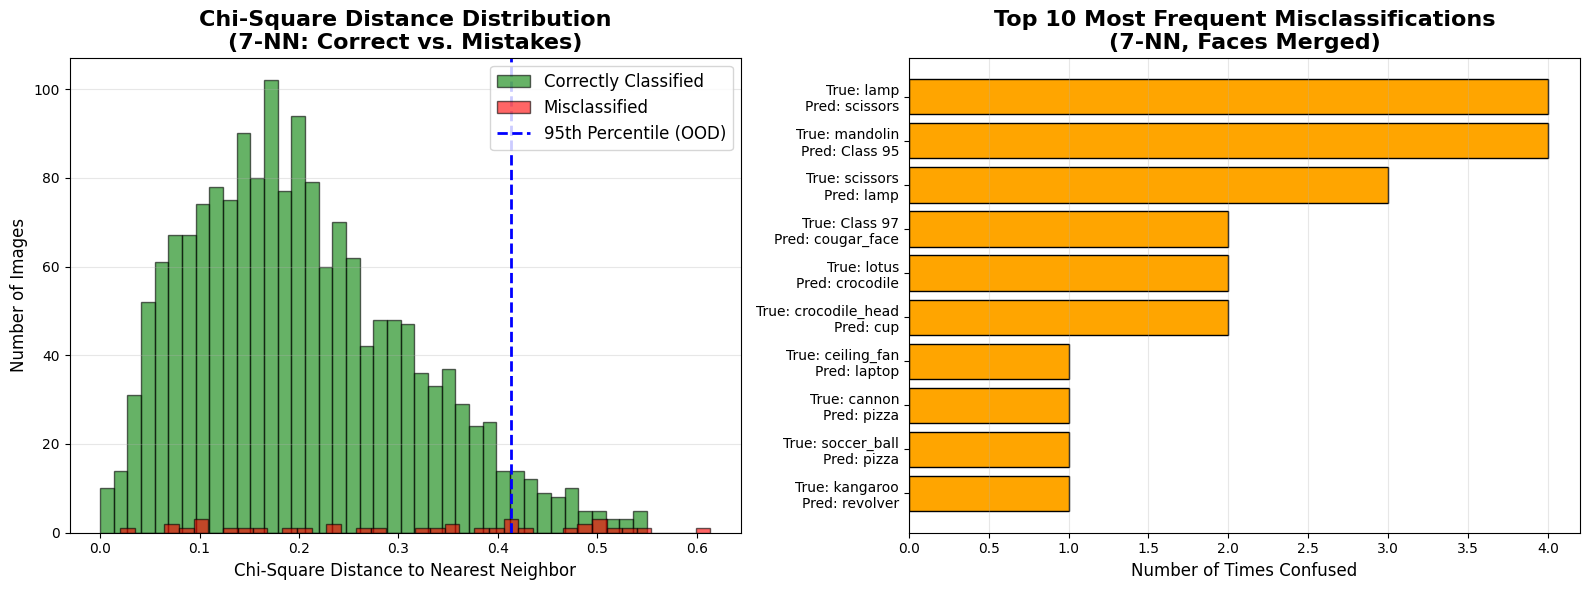

In [161]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.hist(correct_distances, bins=40, alpha=0.6, color='green', edgecolor='black', label='Correctly Classified')
if len(incorrect_distances) > 0:
    ax1.hist(incorrect_distances, bins=40, alpha=0.6, color='red', edgecolor='black', label='Misclassified')

ax1.axvline(np.percentile(all_distances, 95), color='blue', linestyle='dashed', linewidth=2, label='95th Percentile (OOD)')
ax1.set_title(f"Chi-Square Distance Distribution\n({K_NN}-NN: Correct vs. Mistakes)", fontsize=16, fontweight='bold')
ax1.set_xlabel("Chi-Square Distance to Nearest Neighbor", fontsize=12)
ax1.set_ylabel("Number of Images", fontsize=12)
ax1.legend(fontsize=12)
ax1.grid(axis='y', alpha=0.3)

if len(confusion_pairs) > 0:
    mistake_counts = Counter(confusion_pairs).most_common(10)

    def get_class_name(idx):
        if idx < len(class_names):
            return class_names[idx]
        return f"Class {idx}"

    pair_labels = [f"True: {get_class_name(true)}\nPred: {get_class_name(pred)}" for (true, pred), count in mistake_counts]
    counts = [count for (true, pred), count in mistake_counts]

    ax2.barh(pair_labels[::-1], counts[::-1], color='orange', edgecolor='black')
    ax2.set_title(f"Top 10 Most Frequent Misclassifications\n({K_NN}-NN, Faces Merged)", fontsize=16, fontweight='bold')
    ax2.set_xlabel("Number of Times Confused", fontsize=12)
    ax2.grid(axis='x', alpha=0.3)
else:
    ax2.text(0.5, 0.5, 'No Mistakes Found!', ha='center', va='center', fontsize=20)
    ax2.axis('off')

plt.tight_layout()
plt.show()

## **5. OOD Experiments**

In [90]:
import urllib.request
from PIL import Image
import io

In [98]:
import skimage.data # The cheat code!

### **5.1 Data Download**

In [93]:
ood_urls = {
    "Pikachu": "https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/25.png",
    "Mandelbrot_Fractal": "https://upload.wikimedia.org/wikipedia/commons/thumb/2/21/Mandel_zoom_00_mandelbrot_set.jpg/800px-Mandel_zoom_00_mandelbrot_set.jpg",
    "Brain_MRI": "https://upload.wikimedia.org/wikipedia/commons/thumb/a/a1/Normal_axial_T2-weighted_MR_image_of_the_brain.jpg/800px-Normal_axial_T2-weighted_MR_image_of_the_brain.jpg",
    "Spiral_Galaxy": "https://upload.wikimedia.org/wikipedia/commons/thumb/c/c3/NGC_4414_%28NASA-med%29.jpg/800px-NGC_4414_%28NASA-med%29.jpg",
    "Microscopic_Pollen": "https://upload.wikimedia.org/wikipedia/commons/thumb/a/a4/Misc_pollen.jpg/800px-Misc_pollen.jpg"
}

In [99]:
ood_images = {
    "Pikachu": None, # We will download this one below
    "Deep_Space": Image.fromarray(skimage.data.hubble_deep_field()).convert("RGB"),
    "Medical_Cells": Image.fromarray(skimage.data.immunohistochemistry()).convert("RGB"),
    "Text_Document": Image.fromarray(skimage.data.page()).convert("RGB"),
    "Human_Mitosis": Image.fromarray(skimage.data.human_mitosis()).convert("RGB")
}

# 1. Download Pikachu from the PokeAPI (which we know works!)
try:
    url = "https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/25.png"
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as response:
        ood_images["Pikachu"] = Image.open(io.BytesIO(response.read())).convert('RGB')
except Exception as e:
    print(f"Failed to load Pikachu: {e}")

In [100]:
ood_features = []
ood_names = []

In [101]:
num_registers = getattr(model.config, "num_register_tokens", 4)
print(f"Skipping 1 CLS token + {num_registers} Register tokens...")

Skipping 1 CLS token + 4 Register tokens...


### **5.2 Evaluation**

In [103]:
model.eval()
with torch.no_grad():
    for name, img in ood_images.items():
        if img is None:
            continue
        try:
            print(f"   -> Processing {name}...")

            # Pass through your DINOv3 pipeline
            pixel_values = transform(img).unsqueeze(0).to(model.device)
            outputs = model(pixel_values)
            last_hidden_state = outputs.last_hidden_state

            # Slice off CLS and Registers
            patch_tokens = last_hidden_state[0, 1 + num_registers:]

            ood_features.append(patch_tokens.cpu())
            ood_names.append(name)
            print(f"      ✅ Success!")

        except Exception as e:
            print(f"   ❌ Failed to process {name}: {e}")

   -> Processing Pikachu...
      ✅ Success!
   -> Processing Deep_Space...
      ✅ Success!
   -> Processing Medical_Cells...
      ✅ Success!
   -> Processing Text_Document...
      ✅ Success!
   -> Processing Human_Mitosis...
      ✅ Success!


In [104]:
print(f"\n🎉 Successfully extracted patches for {len(ood_names)} OOD images!")


🎉 Successfully extracted patches for 6 OOD images!


### **5.3 Classification**

In [149]:
K_NN = 7

In [162]:
ood_feats_np = to_numpy_array(ood_features)

In [163]:
ood_hists = []
for feats in ood_feats_np:
    feats_f32 = feats.reshape(-1, d).astype(np.float32)
    _, I = index.search(feats_f32, 1) # Find closest visual words
    hist = np.bincount(I.flatten(), minlength=k)
    ood_hists.append(hist)

ood_hists = np.array(ood_hists)

ood_l1 = ood_hists / (np.sum(ood_hists, axis=1, keepdims=True) + 1e-10)

In [164]:
ood_hists = np.array(ood_hists)

# 2. L1 Normalize for Chi-Square distance math
ood_l1 = ood_hists / (np.sum(ood_hists, axis=1, keepdims=True) + 1e-10)

print(f"🚀 RUNNING OOD {K_NN}-NN CHI-SQUARE ANALYSIS...\n")

🚀 RUNNING OOD 7-NN CHI-SQUARE ANALYSIS...



In [165]:
for o_idx, ood_name in enumerate(ood_names):
    ood_vec = ood_l1[o_idx]

    # Calculate Chi-Square distance against ALL Caltech-101 Training Images
    numerator = (train_l1 - ood_vec) ** 2
    denominator = train_l1 + ood_vec + 1e-10
    distances = 0.5 * np.sum(numerator / denominator, axis=1)

    # Get the top K_NN closest matches
    nearest_indices = np.argsort(distances)[:K_NN]
    nearest_distances = distances[nearest_indices]

    # Map back to Caltech-101 string labels, applying the Face merge
    raw_nearest_labels = [int(y_train[idx]) for idx in nearest_indices]
    mapped_labels = [PRIMARY_FACE_ID if lbl in FACES_GROUP else lbl for lbl in raw_nearest_labels]
    nearest_class_names = [get_class_name(lbl) for lbl in mapped_labels]

    # Calculate Statistics
    unique_class_counts = Counter(nearest_class_names)
    pred_class = unique_class_counts.most_common(1)[0][0] # Majority Vote
    num_unique = len(unique_class_counts)
    closest_dist = nearest_distances[0]

    # ------------------------------------------
    # 🖨️ PRINTING THE OOD REPORT
    # ------------------------------------------
    print(f"👽 OOD IMAGE: {ood_name}")
    print(f"   -> Assigned ID Class:       {pred_class}")
    print(f"   -> Closest Distance (1-NN): {closest_dist:.4f}")

    # Optional OOD Flag (Checks if you have an ood_threshold saved from earlier)
    try:
        if closest_dist > np.percentile(all_distances, 95):
            print("      🚨 FLAG: Distance is beyond 95th Percentile! (Detected as OOD)")
    except NameError:
        pass

    print(f"   -> Unique Neighbor Classes: {num_unique} (out of {K_NN} total neighbors)")

    # Formats the breakdown exactly how you asked: "Rat (2), Chicken (1)"
    breakdown_str = ", ".join([f"{name} ({count})" for name, count in unique_class_counts.items()])
    print(f"   -> Neighbor Breakdown:      {breakdown_str}")
    print("-" * 75)

👽 OOD IMAGE: Pikachu
   -> Assigned ID Class:       binocular
   -> Closest Distance (1-NN): 0.5456
      🚨 FLAG: Distance is beyond 95th Percentile! (Detected as OOD)
   -> Unique Neighbor Classes: 6 (out of 7 total neighbors)
   -> Neighbor Breakdown:      binocular (2), elephant (1), cellphone (1), stegosaurus (1), stapler (1), metronome (1)
---------------------------------------------------------------------------
👽 OOD IMAGE: Pikachu
   -> Assigned ID Class:       binocular
   -> Closest Distance (1-NN): 0.5456
      🚨 FLAG: Distance is beyond 95th Percentile! (Detected as OOD)
   -> Unique Neighbor Classes: 6 (out of 7 total neighbors)
   -> Neighbor Breakdown:      binocular (2), elephant (1), cellphone (1), stegosaurus (1), stapler (1), metronome (1)
---------------------------------------------------------------------------
👽 OOD IMAGE: Deep_Space
   -> Assigned ID Class:       binocular
   -> Closest Distance (1-NN): 0.5321
      🚨 FLAG: Distance is beyond 95th Percentile! (

## **6. TD-IDF with Cosine Similiarity**

In [77]:
from sklearn.feature_extraction.text import TfidfTransformer

In [203]:
K_NN = 7
print(f"🔥 Initializing TF-IDF + Cosine Similarity with {K_NN}-NN Majority Voting...")

🔥 Initializing TF-IDF + Cosine Similarity with 7-NN Majority Voting...


### **6.1 Variables**

In [204]:
tfidf_transformer = TfidfTransformer()
train_tfidf = tfidf_transformer.fit_transform(train_hists).toarray().astype(np.float32)
test_tfidf = tfidf_transformer.transform(test_hists).toarray().astype(np.float32)

In [205]:
faiss.normalize_L2(train_tfidf)
faiss.normalize_L2(test_tfidf)

In [206]:
FACES_GROUP = []
for face_name in ['Faces', 'Faces_easy']:
    if face_name in class_names:
        FACES_GROUP.append(class_names.index(face_name))
PRIMARY_FACE_ID = FACES_GROUP[0] if len(FACES_GROUP) > 0 else -1

In [207]:
correct_sims = []
incorrect_sims = []
confusion_pairs = []
correct_count = 0
correct_neighbor_counts = []

In [208]:
print("📐 Calculating Cosine Similarities across the dataset...")
# Vectorized Matrix Multiplication to get Cosine Similarities for all images at once!
# Shape: (num_test, num_train)
similarity_matrix = np.dot(test_tfidf, train_tfidf.T)

📐 Calculating Cosine Similarities across the dataset...


### **6.2 Evaluation**

In [209]:
for t_idx in range(len(test_tfidf)):
    similarities = similarity_matrix[t_idx]

    # Sort Descending (Highest Similarity First!)
    nearest_indices = np.argsort(-similarities)[:K_NN]
    max_sim = similarities[nearest_indices[0]]

    true_label = int(y_test[t_idx])
    raw_nearest_labels = [int(y_train[idx]) for idx in nearest_indices]

    # Merge the Face classes
    mapped_nearest_labels = [PRIMARY_FACE_ID if lbl in FACES_GROUP else lbl for lbl in raw_nearest_labels]
    mapped_true_label = PRIMARY_FACE_ID if true_label in FACES_GROUP else true_label

    # Majority Vote
    pred_label = Counter(mapped_nearest_labels).most_common(1)[0][0]

    if pred_label == mapped_true_label:
        correct_count += 1
        correct_sims.append(max_sim)

        # 🌟 NEW: Count how many of the K neighbors matched the true label
        num_correct_in_k = mapped_nearest_labels.count(mapped_true_label)
        correct_neighbor_counts.append(num_correct_in_k)

    else:
        incorrect_sims.append(max_sim)
        confusion_pairs.append((mapped_true_label, pred_label))

### **6.3 Results**

In [210]:
all_sims = np.array(correct_sims + incorrect_sims)
accuracy = (correct_count / len(test_tfidf)) * 100

# ==========================================
# 🏆 THE ADVANCED STATISTICS (SIMILARITY) 🏆
# ==========================================
print("\n========================================================")
print(f"🎯 TF-IDF {K_NN}-NN ACCURACY: {accuracy:.2f}% ({correct_count}/{len(test_tfidf)} correct)")
print("========================================================")
print("📊 OVERALL SIMILARITY METRICS (OOD THRESHOLDS):")
print(f"   -> 5th Percentile Similarity:    {np.percentile(all_sims, 5):.4f}  <-- BELOW this is OOD!")
print(f"   -> 1st Percentile Similarity:    {np.percentile(all_sims, 1):.4f}  <-- Absolute alien!")
print("--------------------------------------------------------")
print("✅ CORRECT PREDICTIONS:")
print(f"   -> Highest Similarity (Most Sure):  {np.max(correct_sims):.4f}")
print(f"   -> Average (Mean) Similarity:       {np.mean(correct_sims):.4f}")
print(f"   -> Lowest Similarity (Least Sure):  {np.min(correct_sims):.4f}")


🎯 TF-IDF 7-NN ACCURACY: 97.06% (1685/1736 correct)
📊 OVERALL SIMILARITY METRICS (OOD THRESHOLDS):
   -> 5th Percentile Similarity:    0.7393  <-- BELOW this is OOD!
   -> 1st Percentile Similarity:    0.6218  <-- Absolute alien!
--------------------------------------------------------
✅ CORRECT PREDICTIONS:
   -> Highest Similarity (Most Sure):  1.0000
   -> Average (Mean) Similarity:       0.9069
   -> Lowest Similarity (Least Sure):  0.4400


In [211]:
if len(correct_neighbor_counts) > 0:
    avg_correct_neighbors = np.mean(correct_neighbor_counts)
    print(f"   -> 🧠 Neighborhood Purity:        {avg_correct_neighbors:.2f} / {K_NN} neighbors correct on average")

   -> 🧠 Neighborhood Purity:        6.86 / 7 neighbors correct on average


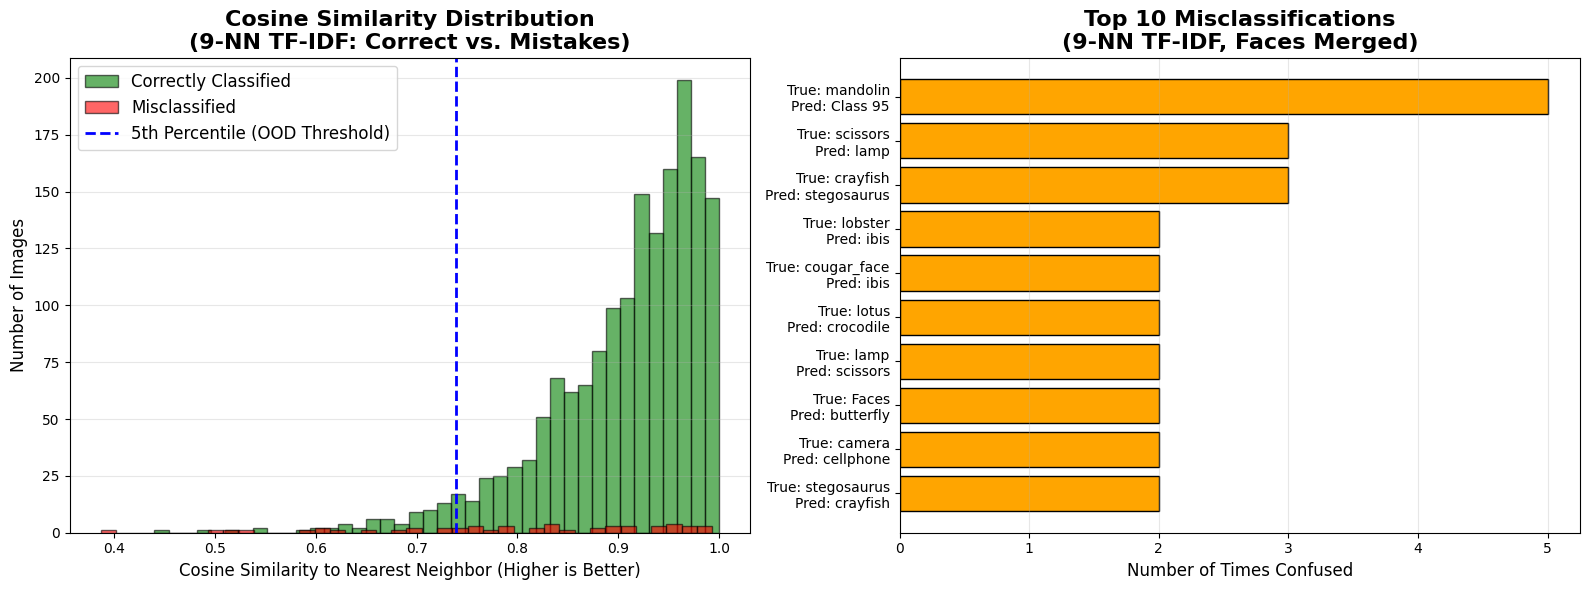

In [202]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- PLOT 1: Similarity Distributions ---
ax1.hist(correct_sims, bins=40, alpha=0.6, color='green', edgecolor='black', label='Correctly Classified')
if len(incorrect_sims) > 0:
    ax1.hist(incorrect_sims, bins=40, alpha=0.6, color='red', edgecolor='black', label='Misclassified')

# The OOD Threshold line is now on the LEFT side of the graph
ood_threshold = np.percentile(all_sims, 5)
ax1.axvline(ood_threshold, color='blue', linestyle='dashed', linewidth=2, label='5th Percentile (OOD Threshold)')
ax1.set_title(f"Cosine Similarity Distribution\n({K_NN}-NN TF-IDF: Correct vs. Mistakes)", fontsize=16, fontweight='bold')
ax1.set_xlabel("Cosine Similarity to Nearest Neighbor (Higher is Better)", fontsize=12)
ax1.set_ylabel("Number of Images", fontsize=12)
ax1.legend(fontsize=12)
ax1.grid(axis='y', alpha=0.3)

# --- PLOT 2: Top Confusions ---
if len(confusion_pairs) > 0:
    mistake_counts = Counter(confusion_pairs).most_common(10)

    def get_class_name(idx):
        if idx < len(class_names):
            return class_names[idx]
        return f"Class {idx}"

    pair_labels = [f"True: {get_class_name(true)}\nPred: {get_class_name(pred)}" for (true, pred), count in mistake_counts]
    counts = [count for (true, pred), count in mistake_counts]

    ax2.barh(pair_labels[::-1], counts[::-1], color='orange', edgecolor='black')
    ax2.set_title(f"Top 10 Misclassifications\n({K_NN}-NN TF-IDF, Faces Merged)", fontsize=16, fontweight='bold')
    ax2.set_xlabel("Number of Times Confused", fontsize=12)
    ax2.grid(axis='x', alpha=0.3)
else:
    ax2.text(0.5, 0.5, 'No Mistakes Found!', ha='center', va='center', fontsize=20)
    ax2.axis('off')

plt.tight_layout()
plt.show()

## **7. OOD with TD-IDF**

In [223]:
K_NN = 9

In [224]:
# Cluster using your existing FAISS 'index'
ood_feats_np = to_numpy_array(ood_features)

In [225]:
ood_hists_raw = []
for feats in ood_feats_np:
    feats_f32 = feats.reshape(-1, d).astype(np.float32)
    _, I = index.search(feats_f32, 1)
    hist = np.bincount(I.flatten(), minlength=k)
    ood_hists_raw.append(hist)

ood_hists_raw = np.array(ood_hists_raw)

In [226]:
ood_tfidf = tfidf_transformer.transform(ood_hists_raw).toarray().astype(np.float32)

# L2 Normalize for Cosine Similarity
faiss.normalize_L2(ood_tfidf)

In [227]:
# Vectorized Cosine Similarity calculation (Dot Product of L2 Normalized vectors)
# Shape: (num_ood_images, num_train_images)
ood_similarity_matrix = np.dot(ood_tfidf, train_tfidf.T)

In [228]:
for o_idx, ood_name in enumerate(ood_names):
    similarities = ood_similarity_matrix[o_idx]

    # Sort DESCENDING (Highest Similarity First!)
    nearest_indices = np.argsort(-similarities)[:K_NN]
    nearest_sims = similarities[nearest_indices]

    # Map back to Caltech-101 string labels, applying the Face merge
    raw_nearest_labels = [int(y_train[idx]) for idx in nearest_indices]
    mapped_labels = [PRIMARY_FACE_ID if lbl in FACES_GROUP else lbl for lbl in raw_nearest_labels]
    nearest_class_names = [get_class_name(lbl) for lbl in mapped_labels]

    # Calculate Statistics
    unique_class_counts = Counter(nearest_class_names)
    pred_class = unique_class_counts.most_common(1)[0][0] # Majority Vote
    num_unique = len(unique_class_counts)
    highest_sim = nearest_sims[0] # The 1-NN equivalent

    # ------------------------------------------
    # 🖨️ PRINTING THE OOD REPORT
    # ------------------------------------------
    print(f"👽 OOD IMAGE: {ood_name}")
    print(f"   -> Assigned ID Class:          {pred_class}")
    print(f"   -> Highest Similarity (1-NN):  {highest_sim:.4f}")

    # OOD Flag based on Cosine Similarity
    try:
        # We want to flag it if the similarity is completely pathetic (below 5th percentile of normal data)
        threshold_5th = np.percentile(all_sims, 5)
        if highest_sim < threshold_5th:
            print(f"      🚨 FLAG: Similarity is incredibly low (Below 5th Percentile: {threshold_5th:.4f})! Detected as OOD.")
        else:
            print(f"      ⚠️ WARNING: The model thinks this is normal data (Similarity higher than 5th percentile).")
    except NameError:
        pass

    print(f"   -> Unique Neighbor Classes:    {num_unique} (out of {K_NN} total neighbors)")

    ordered_list_str = " ➔ ".join(nearest_class_names)
    print(f"   -> Exact {K_NN} Sequence:         {ordered_list_str}")

    breakdown_str = ", ".join([f"{name} ({count})" for name, count in unique_class_counts.items()])
    print(f"   -> Neighbor Breakdown:         {breakdown_str}")
    print("-" * 85)

👽 OOD IMAGE: Pikachu
   -> Assigned ID Class:          cellphone
   -> Highest Similarity (1-NN):  0.7164
      🚨 FLAG: Similarity is incredibly low (Below 5th Percentile: 0.7393)! Detected as OOD.
   -> Unique Neighbor Classes:    8 (out of 9 total neighbors)
   -> Exact 9 Sequence:         elephant ➔ cellphone ➔ anchor ➔ binocular ➔ stegosaurus ➔ Class 100 ➔ llama ➔ crayfish ➔ cellphone
   -> Neighbor Breakdown:         elephant (1), cellphone (2), anchor (1), binocular (1), stegosaurus (1), Class 100 (1), llama (1), crayfish (1)
-------------------------------------------------------------------------------------
👽 OOD IMAGE: Pikachu
   -> Assigned ID Class:          cellphone
   -> Highest Similarity (1-NN):  0.7164
      🚨 FLAG: Similarity is incredibly low (Below 5th Percentile: 0.7393)! Detected as OOD.
   -> Unique Neighbor Classes:    8 (out of 9 total neighbors)
   -> Exact 9 Sequence:         elephant ➔ cellphone ➔ anchor ➔ binocular ➔ stegosaurus ➔ Class 100 ➔ llama ➔ crayf